In [6]:
import pandas as pd

In [9]:
df = pd.read_csv("/Users/meghanagowda/Downloads/Medicaldataset.csv")
df.head(5)

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,Result
0,64,1,66,160,83,160.0,1.80,0.012,negative
1,21,1,94,98,46,296.0,6.75,1.060,positive
2,55,1,64,160,77,270.0,1.99,0.003,negative
3,64,1,70,120,55,270.0,13.87,0.122,positive
4,55,1,64,112,65,300.0,1.08,0.003,negative


In [10]:
df.tail(3)

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,Result
1316,45,1,85,168,104,96.0,1.24,4.250,positive
1317,54,1,58,117,68,443.0,5.80,0.359,positive
1318,51,1,94,157,79,134.0,50.89,1.770,positive


In [11]:
df.head()

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,Result
0,64,1,66,160,83,160.0,1.80,0.012,negative
1,21,1,94,98,46,296.0,6.75,1.060,positive
2,55,1,64,160,77,270.0,1.99,0.003,negative
3,64,1,70,120,55,270.0,13.87,0.122,positive
4,55,1,64,112,65,300.0,1.08,0.003,negative


In [12]:
df.shape

(1319, 9)

In [13]:
df.columns

Index(['Age', 'Gender', 'Heart rate', 'Systolic blood pressure',
       'Diastolic blood pressure', 'Blood sugar', 'CK-MB', 'Troponin',
       'Result'],
      dtype='str')

In [14]:
df.dtypes

Age                           int64
Gender                        int64
Heart rate                    int64
Systolic blood pressure       int64
Diastolic blood pressure      int64
Blood sugar                 float64
CK-MB                       float64
Troponin                    float64
Result                          str
dtype: object

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1319 entries, 0 to 1318
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1319 non-null   int64  
 1   Gender                    1319 non-null   int64  
 2   Heart rate                1319 non-null   int64  
 3   Systolic blood pressure   1319 non-null   int64  
 4   Diastolic blood pressure  1319 non-null   int64  
 5   Blood sugar               1319 non-null   float64
 6   CK-MB                     1319 non-null   float64
 7   Troponin                  1319 non-null   float64
 8   Result                    1319 non-null   str    
dtypes: float64(3), int64(5), str(1)
memory usage: 103.2 KB


In [17]:
df.isnull().sum()

Age                         0
Gender                      0
Heart rate                  0
Systolic blood pressure     0
Diastolic blood pressure    0
Blood sugar                 0
CK-MB                       0
Troponin                    0
Result                      0
dtype: int64

In [18]:
numeric_columns = df.select_dtypes(include="number").columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].mean())

In [19]:
df.isnull().sum()

Age                         0
Gender                      0
Heart rate                  0
Systolic blood pressure     0
Diastolic blood pressure    0
Blood sugar                 0
CK-MB                       0
Troponin                    0
Result                      0
dtype: int64

In [20]:
df["Result"] = df["Result"].astype("category")

In [21]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 30, 50, 70, 100],
    labels=["Young", "Adult", "Middle Age", "Senior"]
)

In [22]:
df.head()

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,Result,Age Group
0,64,1,66,160,83,160.0,1.80,0.012,negative,Middle Age
1,21,1,94,98,46,296.0,6.75,1.060,positive,Young
2,55,1,64,160,77,270.0,1.99,0.003,negative,Middle Age
3,64,1,70,120,55,270.0,13.87,0.122,positive,Middle Age
4,55,1,64,112,65,300.0,1.08,0.003,negative,Middle Age


In [23]:
df["Result"].value_counts()

Result
positive    810
negative    509
Name: count, dtype: int64

In [24]:
df.groupby("Result", observed=True)["Age"].mean()

Result
negative    52.094303
positive    58.766667
Name: Age, dtype: float64

In [25]:
df.groupby("Result", observed=True)["Heart rate"].mean()

Result
negative    77.886051
positive    78.619753
Name: Heart rate, dtype: float64

In [26]:
df.groupby("Result", observed=True)["Blood sugar"].mean()

Result
negative    149.757760
positive    144.671605
Name: Blood sugar, dtype: float64

In [27]:
pd.crosstab(df["Age Group"], df["Result"])

Result,negative,positive
Age Group,,
Young,36,25
Adult,204,186
Middle Age,227,478
Senior,42,119


In [28]:
import matplotlib.pyplot as plt

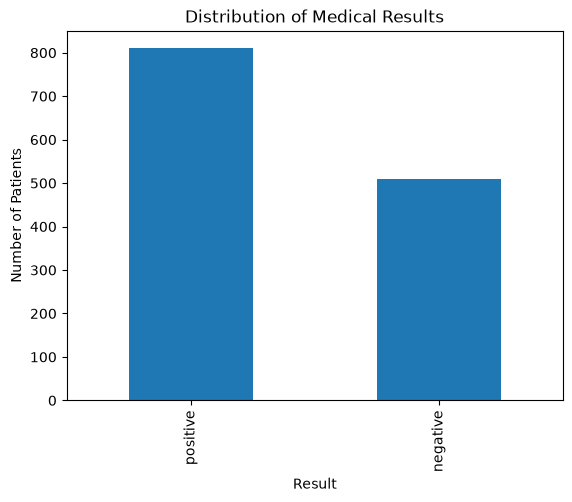

In [29]:
df["Result"].value_counts().plot(kind="bar")

plt.title("Distribution of Medical Results")
plt.xlabel("Result")
plt.ylabel("Number of Patients")
plt.show()

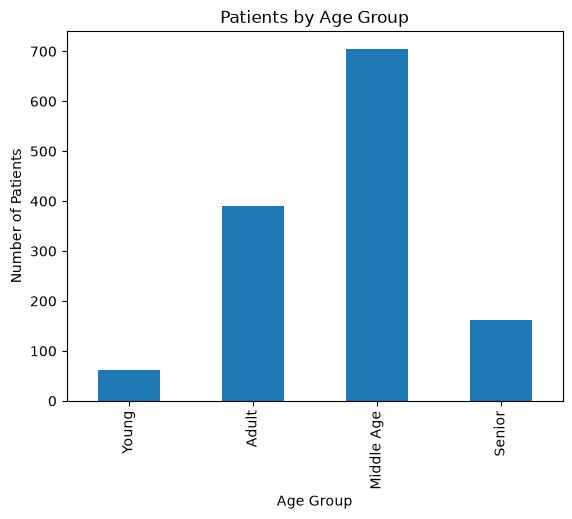

In [30]:
df["Age Group"].value_counts().sort_index().plot(kind="bar")

plt.title("Patients by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")
plt.show()

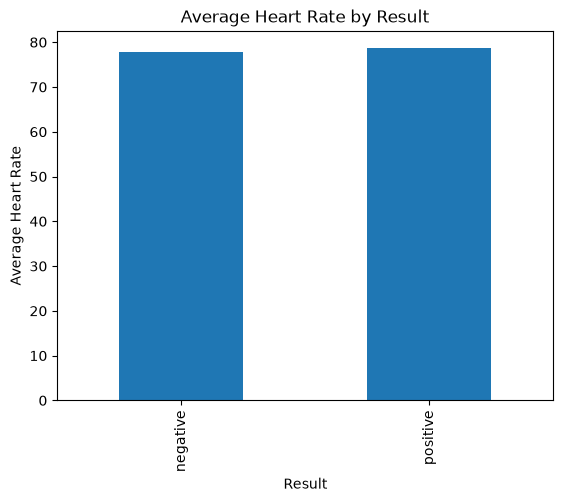

In [31]:
df.groupby("Result", observed=True)["Heart rate"].mean().plot(kind="bar")

plt.title("Average Heart Rate by Result")
plt.xlabel("Result")
plt.ylabel("Average Heart Rate")
plt.show()

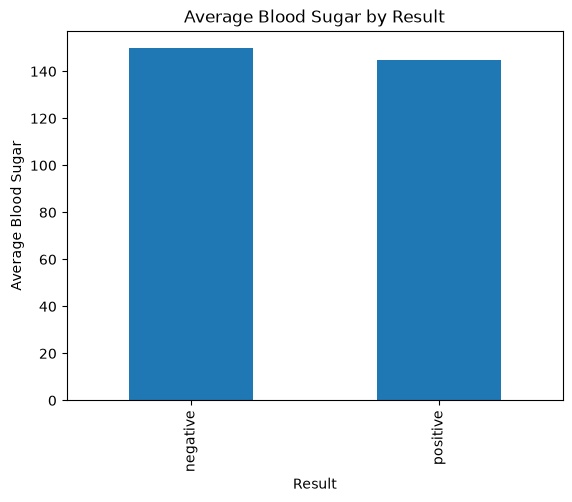

In [32]:
df.groupby("Result", observed=True)["Blood sugar"].mean().plot(kind="bar")

plt.title("Average Blood Sugar by Result")
plt.xlabel("Result")
plt.ylabel("Average Blood Sugar")
plt.show()

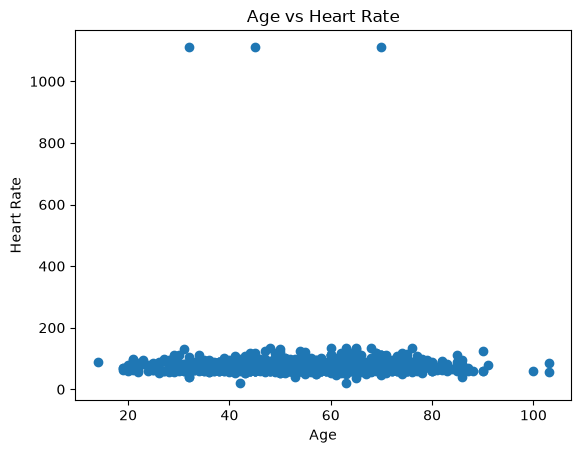

In [33]:
plt.scatter(df["Age"], df["Heart rate"])

plt.title("Age vs Heart Rate")
plt.xlabel("Age")
plt.ylabel("Heart Rate")
plt.show()

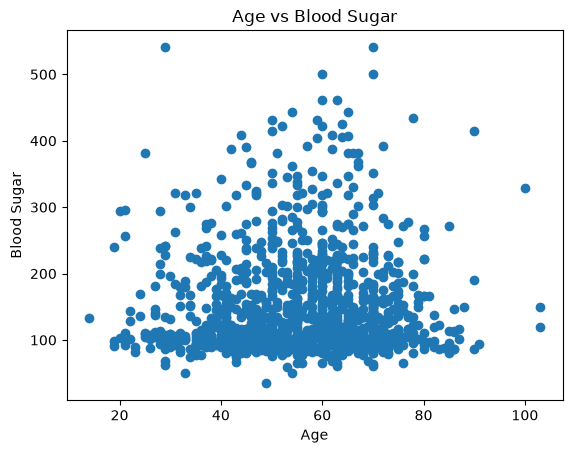

In [34]:
plt.scatter(df["Age"], df["Blood sugar"])

plt.title("Age vs Blood Sugar")
plt.xlabel("Age")
plt.ylabel("Blood Sugar")
plt.show()